In [2]:

import pandas as pd
import numpy as np

# Load both yearly sheets
file_path = "/content/RetailIQ_Final.xlsx"

sheets = pd.read_excel(file_path, sheet_name=None)

# Combine both years for overall analysis
df_combined = pd.concat(sheets.values(), ignore_index=True)

# Store datasets for analysis
datasets = {
    "Year 2009-2010": sheets["Year 2009-2010"],
    "Year 2010-2011": sheets["Year 2010-2011"],
    "Combined Dataset": df_combined
}

# Dataset overview
for name, df in datasets.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Total Records:", len(df))
    print("Total Columns:", len(df.columns))

    print("Date Range:",
          df["InvoiceDate"].min(),
          "to",
          df["InvoiceDate"].max())

    print("Unique Invoices:", df["InvoiceNo"].nunique())
    print("Unique Products:", df["StockCode"].nunique())
    print("Unique Customers:", df["CustomerID"].nunique())
    print("Unique Countries:", df["Country"].nunique())

    print("Total Quantity:", df["Quantity"].sum())
    print("Total Revenue:", df["Revenue"].sum())

    print("Missing CustomerIDs:", df["CustomerID"].isna().sum())
    print("Missing Descriptions:", df["Description"].isna().sum())



Year 2009-2010
Total Records: 518596
Total Columns: 14
Date Range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Unique Invoices: 28816
Unique Products: 4632
Unique Customers: 4383
Unique Countries: 40
Total Quantity: 5413184
Total Revenue: 10271762.664
Missing CustomerIDs: 107833
Missing Descriptions: 2928

Year 2010-2011
Total Records: 536642
Total Columns: 14
Date Range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique Invoices: 25900
Unique Products: 4070
Unique Customers: 4372
Unique Countries: 38
Total Quantity: 5162503
Total Revenue: 10642128.804
Missing CustomerIDs: 135037
Missing Descriptions: 1454

Combined Dataset
Total Records: 1055238
Total Columns: 14
Date Range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique Invoices: 53628
Unique Products: 5305
Unique Customers: 5942
Unique Countries: 43
Total Quantity: 10575687
Total Revenue: 20913891.468000002
Missing CustomerIDs: 242870
Missing Descriptions: 4382


In [3]:

import pandas as pd
import numpy as np

# Store yearly and combined datasets
datasets = {
    "Year 2009-2010": sheets["Year 2009-2010"],
    "Year 2010-2011": sheets["Year 2010-2011"],
    "Combined Dataset": df_combined
}

sales_summary = []

for name, df in datasets.items():

    total_revenue = df["Revenue"].sum()

    # Exclude cancelled invoices from order count
    total_orders = df.loc[
        ~df["IsCancelled"], "InvoiceNo"
    ].nunique()

    total_quantity = df["Quantity"].sum()

    average_order_value = (
        total_revenue / total_orders
        if total_orders > 0 else 0
    )

    sales_summary.append({
        "Dataset": name,
        "Total Revenue": total_revenue,
        "Total Orders": total_orders,
        "Total Quantity": total_quantity,
        "Average Order Value": average_order_value
    })

sales_summary_df = pd.DataFrame(sales_summary)

print(sales_summary_df.to_string(index=False))


         Dataset  Total Revenue  Total Orders  Total Quantity  Average Order Value
  Year 2009-2010   10271762.664         24224         5413184           424.032475
  Year 2010-2011   10642128.804         22064         5162503           482.329986
Combined Dataset   20913891.468         45336        10575687           461.308705


In [4]:

for name, df in datasets.items():

    print("\n==========", name, "==========")

    monthly_revenue = (
        df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"]
        .sum()
        .reset_index()
    )

    monthly_revenue.columns = ["Month", "Revenue"]

    print("\nMonthly Revenue:")
    print(monthly_revenue.to_string(index=False))

    print("\nHighest Revenue Month:")
    print(monthly_revenue.loc[
        monthly_revenue["Revenue"].idxmax()
    ])

    print("\nLowest Revenue Month:")
    print(monthly_revenue.loc[
        monthly_revenue["Revenue"].idxmin()
    ])



========== Year 2009-2010 ==========

Monthly Revenue:
  Month     Revenue
2009-12  822483.950
2010-01  651155.112
2010-02  551504.726
2010-03  830915.261
2010-04  678875.252
2010-05  657705.500
2010-06  749537.310
2010-07  648810.270
2010-08  695251.910
2010-09  921696.991
2010-10 1161902.220
2010-11 1464293.142
2010-12  437631.020

Highest Revenue Month:
Month          2010-11
Revenue    1464293.142
Name: 11, dtype: object

Lowest Revenue Month:
Month        2010-12
Revenue    437631.02
Name: 12, dtype: object

========== Year 2010-2011 ==========

Monthly Revenue:
  Month     Revenue
2010-12  821452.730
2011-01  689811.610
2011-02  522545.560
2011-03  716215.260
2011-04  536968.491
2011-05  769296.610
2011-06  760547.010
2011-07  718076.121
2011-08  757841.380
2011-09 1056435.192
2011-10 1151263.730
2011-11 1503866.780
2011-12  637808.330

Highest Revenue Month:
Month         2011-11
Revenue    1503866.78
Name: 11, dtype: object

Lowest Revenue Month:
Month        2011-02
Revenue  

In [5]:
df1 = sheets["Year 2009-2010"]
df2 = sheets["Year 2010-2011"]

# Identify overlapping invoice numbers
invoices1 = set(df1["InvoiceNo"].dropna().unique())
invoices2 = set(df2["InvoiceNo"].dropna().unique())

overlapping_invoices = invoices1.intersection(invoices2)

print("Overlapping Invoice Numbers:", len(overlapping_invoices))

# Extract records belonging to overlapping invoices
overlap_df1 = df1[df1["InvoiceNo"].isin(overlapping_invoices)]
overlap_df2 = df2[df2["InvoiceNo"].isin(overlapping_invoices)]

print("Records in first sheet:", len(overlap_df1))
print("Records in second sheet:", len(overlap_df2))

# Compare exact duplicate records across sheets
common_records = pd.merge(
    overlap_df1,
    overlap_df2,
    how="inner"
)

print("Exact matching records across sheets:", len(common_records))

Overlapping Invoice Numbers: 1088
Records in first sheet: 22202
Records in second sheet: 22202
Exact matching records across sheets: 22202


In [6]:
# Combine both yearly datasets
df_combined = pd.concat(
    [df1, df2],
    ignore_index=True
)

# Remove exact duplicate records across sheets
df_combined = df_combined.drop_duplicates().reset_index(drop=True)

print("Corrected Combined Records:", len(df_combined))
print("Remaining Duplicate Records:", df_combined.duplicated().sum())
print("Corrected Combined Revenue:", df_combined["Revenue"].sum())

Corrected Combined Records: 1033036
Remaining Duplicate Records: 0
Corrected Combined Revenue: 20476260.448000003


In [7]:
datasets = {
    "Year 2009-2010": df1,
    "Year 2010-2011": df2,
    "Combined Dataset": df_combined
}

In [8]:
total_revenue = df_combined["Revenue"].sum()

total_orders = df_combined.loc[
    ~df_combined["IsCancelled"], "InvoiceNo"
].nunique()

total_quantity = df_combined["Quantity"].sum()

average_order_value = total_revenue / total_orders

print("Corrected Combined Sales Summary")
print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Total Quantity:", total_quantity)
print("Average Order Value:", average_order_value)

Corrected Combined Sales Summary
Total Revenue: 20476260.448000003
Total Orders: 45336
Total Quantity: 10409779
Average Order Value: 451.65564778542443


In [9]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    customer_count = df["CustomerID"].nunique()

    print("Unique Customers:", customer_count)

    customer_revenue = (
        df.groupby("CustomerID")["Revenue"]
        .sum()
        .sort_values(ascending=False)
    )

    print("\nTop 10 Customers by Revenue:")
    print(customer_revenue.head(10))


========== Year 2009-2010 ==========
Unique Customers: 4383

Top 10 Customers by Revenue:
CustomerID
18102.0    349164.35
14646.0    248396.50
14156.0    196549.74
14911.0    152121.22
13694.0    131443.19
17511.0     84541.17
15061.0     83284.38
16684.0     80489.21
16754.0     65500.07
17949.0     60117.60
Name: Revenue, dtype: float64

========== Year 2010-2011 ==========
Unique Customers: 4372

Top 10 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

========== Combined Dataset ==========
Unique Customers: 5942

Top 10 Customers by Revenue:
CustomerID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Na

In [10]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    customer_orders = (
        df[~df["IsCancelled"]]
        .groupby("CustomerID")["InvoiceNo"]
        .nunique()
        .sort_values(ascending=False)
    )

    print("Top 10 Customers by Order Frequency:")
    print(customer_orders.head(10))


========== Year 2009-2010 ==========
Top 10 Customers by Order Frequency:
CustomerID
14911.0    205
17850.0    155
12748.0    144
15311.0    121
13089.0    109
14606.0    102
14156.0    102
13694.0     94
17841.0     91
18102.0     89
Name: InvoiceNo, dtype: int64

========== Year 2010-2011 ==========
Top 10 Customers by Order Frequency:
CustomerID
12748.0    210
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     74
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

========== Combined Dataset ==========
Top 10 Customers by Order Frequency:
CustomerID
14911.0    398
12748.0    337
17841.0    211
15311.0    208
13089.0    203
14606.0    192
14156.0    156
17850.0    155
14646.0    152
18102.0    145
Name: InvoiceNo, dtype: int64


In [11]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    customer_revenue = (
        df.groupby("CustomerID")["Revenue"]
        .sum()
        .sort_values(ascending=False)
    )

    # Remove missing CustomerIDs
    customer_revenue = customer_revenue.dropna()

    total_customer_revenue = customer_revenue.sum()

    top_10_revenue = customer_revenue.head(10).sum()

    contribution = (
        top_10_revenue / total_customer_revenue
    ) * 100

    print("Total Identified Customer Revenue:",
          round(total_customer_revenue, 2))

    print("Top 10 Customers Revenue:",
          round(top_10_revenue, 2))

    print("Top 10 Revenue Contribution:",
          round(contribution, 2), "%")


========== Year 2009-2010 ==========
Total Identified Customer Revenue: 8798233.74
Top 10 Customers Revenue: 1451607.43
Top 10 Revenue Contribution: 16.5 %

========== Year 2010-2011 ==========
Total Identified Customer Revenue: 8887226.89
Top 10 Customers Revenue: 1537659.21
Top 10 Revenue Contribution: 17.3 %

========== Combined Dataset ==========
Total Identified Customer Revenue: 17374804.27
Top 10 Customers Revenue: 2787079.44
Top 10 Revenue Contribution: 16.04 %


In [12]:
# Reference date: one day after the latest transaction
reference_date = df_combined["InvoiceDate"].max() + pd.Timedelta(days=1)

# Exclude cancelled invoices and missing CustomerIDs
customer_data = df_combined[
    (~df_combined["IsCancelled"]) &
    (df_combined["CustomerID"].notna())
]

rfm = customer_data.groupby("CustomerID").agg({

    "InvoiceDate": lambda x: (reference_date - x.max()).days,

    "InvoiceNo": "nunique",

    "Revenue": "sum"

})

rfm.columns = ["Recency", "Frequency", "Monetary"]

print(rfm.head())
print("\nRFM Shape:", rfm.shape)

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326         12  77556.46
12347.0           2          8   4921.53
12348.0          75          5   2019.40
12349.0          19          4   4428.69
12350.0         310          1    334.40

RFM Shape: (5881, 3)


In [13]:
# Assign RFM scores from 1 to 5
# Rank-based scoring handles repeated values without qcut errors.

rfm["R_Score"] = 6 - np.ceil(
    rfm["Recency"].rank(pct=True) * 5
)

rfm["F_Score"] = np.ceil(
    rfm["Frequency"].rank(pct=True) * 5
)

rfm["M_Score"] = np.ceil(
    rfm["Monetary"].rank(pct=True) * 5
)

# Convert scores to integers
rfm[["R_Score", "F_Score", "M_Score"]] = (
    rfm[["R_Score", "F_Score", "M_Score"]].astype(int)
)

# Create combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

print(rfm.head(10))

            Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
CustomerID                                                                   
12346.0         326         12  77556.46        2        5        5       255
12347.0           2          8   4921.53        5        4        5       545
12348.0          75          5   2019.40        3        4        4       344
12349.0          19          4   4428.69        5        3        5       535
12350.0         310          1    334.40        2        1        2       212
12351.0         375          1    300.93        2        1        2       212
12352.0          36         10   2849.84        4        5        4       454
12353.0         204          2    406.76        2        2        2       222
12354.0         232          1   1079.40        2        1        3       213
12355.0         214          2    947.61        2        2        3       223


In [14]:
def segment_customer(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r == 5 and f == 1:
        return "New Customers"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Hibernating"

    elif r == 3 and f <= 3:
        return "Need Attention"

    else:
        return "Others"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

# Display segment counts
segment_summary = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["Customer Segment", "Customer Count"]

segment_summary["Percentage"] = (
    segment_summary["Customer Count"] / len(rfm) * 100
).round(2)

print(segment_summary.to_string(index=False))

   Customer Segment  Customer Count  Percentage
        Hibernating            1646       27.99
          Champions            1274       21.66
    Loyal Customers             887       15.08
Potential Loyalists             712       12.11
     Need Attention             698       11.87
            At Risk             424        7.21
             Others             164        2.79
      New Customers              76        1.29


In [15]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    product_revenue = (
        df.groupby(["StockCode", "Description"])["Revenue"]
        .sum()
        .sort_values(ascending=False)
    )

    print("\nTop 10 Products by Revenue:")
    print(product_revenue.head(10))


========== Year 2009-2010 ==========

Top 10 Products by Revenue:
StockCode  Description                        
M          Manual                                 262577.36
22423      REGENCY CAKESTAND 3 TIER               169912.76
85123A     WHITE HANGING HEART T-LIGHT HOLDER     158305.72
DOT        DOTCOM POSTAGE                         116408.71
84879      ASSORTED COLOUR BIRD ORNAMENT           72890.19
22086      PAPER CHAIN KIT 50'S CHRISTMAS          58127.30
85099B     JUMBO BAG RED RETROSPOT                 54368.82
47566      PARTY BUNTING                           49664.12
POST       POSTAGE                                 49477.54
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     47954.49
Name: Revenue, dtype: float64

========== Year 2010-2011 ==========

Top 10 Products by Revenue:
StockCode  Description                       
DOT        DOTCOM POSTAGE                        206248.77
22423      REGENCY CAKESTAND 3 TIER              174156.54
23843      PAPER CRAFT , 

In [16]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    product_quantity = (
        df.groupby(["StockCode", "Description"])["Quantity"]
        .sum()
        .sort_values(ascending=False)
    )

    print("\nTop 10 Products by Quantity Sold:")
    print(product_quantity.head(10))


========== Year 2009-2010 ==========

Top 10 Products by Quantity Sold:
StockCode  Description                       
85123A     WHITE HANGING HEART T-LIGHT HOLDER    57327
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     54554
17003      BROCADE RING PURSE                    47647
21212      PACK OF 72 RETRO SPOT CAKE CASES      46079
84879      ASSORTED COLOUR BIRD ORNAMENT         44805
84991      60 TEATIME FAIRY CAKE CASES           36172
21977      PACK OF 60 PINK PAISLEY CAKE CASES    31687
85099B     JUMBO BAG RED RETROSPOT               30249
22197      SMALL POPCORN HOLDER                  29485
21232      STRAWBERRY CERAMIC TRINKET BOX        26496
Name: Quantity, dtype: int64

========== Year 2010-2011 ==========

Top 10 Products by Quantity Sold:
StockCode  Description                       
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
85099B     JUMBO BAG RED RETROSPOT               47260
22197      POPCORN HOLDER                        36322
84879      ASSORTE

In [17]:
# Group products using StockCode only
product_quantity = (
    df_combined.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products by Net Quantity:")
print(product_quantity.head(10))

Top 10 Products by Net Quantity:
StockCode
84077     104546
85099B     94151
85123A     94123
21212      93774
84879      78978
22197      77969
17003      69639
21977      55842
84991      53678
22492      43265
Name: Quantity, dtype: int64


In [18]:
# Calculate revenue by StockCode
product_revenue = (
    df_combined.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Total product revenue
total_product_revenue = product_revenue.sum()

# Top 10 products
top_10_products = product_revenue.head(10)

# Revenue contribution
top_10_contribution = (
    top_10_products.sum() / total_product_revenue
) * 100

print("Top 10 Products by Revenue:")
print(top_10_products)

print("\nTotal Revenue:", round(total_product_revenue, 2))

print("Top 10 Revenue Contribution:",
      round(top_10_contribution, 2), "%")

Top 10 Products by Revenue:
StockCode
M         339226.24
22423     330590.32
DOT       309854.11
85123A    257724.71
85099B    180569.34
23843     168469.60
47566     148318.28
84879     129324.49
POST      125682.42
22086     117760.29
Name: Revenue, dtype: float64

Total Revenue: 20476260.45
Top 10 Revenue Contribution: 10.29 %


In [19]:
# Create product revenue for both periods
revenue_1 = (
    df1.groupby(df1["StockCode"].astype(str))["Revenue"]
    .sum()
)

revenue_2 = (
    df2.groupby(df2["StockCode"].astype(str))["Revenue"]
    .sum()
)

# Combine both periods
product_comparison = pd.DataFrame({
    "Revenue_2009_2010": revenue_1,
    "Revenue_2010_2011": revenue_2
}).fillna(0)

# Calculate revenue difference
product_comparison["Revenue_Change"] = (
    product_comparison["Revenue_2010_2011"] -
    product_comparison["Revenue_2009_2010"]
)

# Calculate percentage change
product_comparison["Percentage_Change"] = np.where(
    product_comparison["Revenue_2009_2010"] > 0,
    (
        product_comparison["Revenue_Change"] /
        product_comparison["Revenue_2009_2010"]
    ) * 100,
    np.nan
)

print("Top 10 Products with Highest Revenue Growth:")
print(
    product_comparison.sort_values(
        "Revenue_Change", ascending=False
    ).head(10)
)

print("\nTop 10 Products with Highest Revenue Decline:")
print(
    product_comparison.sort_values(
        "Revenue_Change", ascending=True
    ).head(10)
)

Top 10 Products with Highest Revenue Growth:
           Revenue_2009_2010  Revenue_2010_2011  Revenue_Change  \
StockCode                                                         
23843                   0.00          168469.60       168469.60   
DOT                116408.71          206248.77        89840.06   
23166                   0.00           81700.92        81700.92   
23084                   0.00           66870.03        66870.03   
47566               49664.12           99445.23        49781.11   
23298                   0.00           43148.18        43148.18   
23203                   0.00           42030.34        42030.34   
22502               10057.70           51408.77        41351.07   
23284                   0.00           38133.64        38133.64   
22720                   0.00           38108.89        38108.89   

           Percentage_Change  
StockCode                     
23843                    NaN  
DOT                77.176407  
23166                    N

In [20]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    country_revenue = (
        df.groupby("Country")["Revenue"]
        .sum()
        .sort_values(ascending=False)
    )

    print("\nTop 10 Countries by Revenue:")
    print(country_revenue.head(10))


========== Year 2009-2010 ==========

Top 10 Countries by Revenue:
Country
United Kingdom    8812311.833
EIRE               380909.570
Netherlands        268784.350
Germany            202025.391
France             147103.140
Sweden              53501.990
Denmark             50906.850
Spain               47568.650
Switzerland         43921.390
Australia           31446.800
Name: Revenue, dtype: float64

========== Year 2010-2011 ==========

Top 10 Countries by Revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209643.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

========== Combined Dataset ==========

Top 10 Countries by Revenue:
Country
United Kingdom    1.741020e+07
EIRE              6.587673e+05
Netherlands       5.540381e+05
Germany          

In [21]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    country_orders = (
        df[~df["IsCancelled"]]
        .groupby("Country")["InvoiceNo"]
        .nunique()
        .sort_values(ascending=False)
    )

    print("\nTop 10 Countries by Orders:")
    print(country_orders.head(10))


========== Year 2009-2010 ==========

Top 10 Countries by Orders:
Country
United Kingdom    22563
EIRE                348
Germany             347
France              241
Netherlands         135
Sweden               69
Spain                66
Belgium              52
Portugal             41
Switzerland          40
Name: InvoiceNo, dtype: int64

========== Year 2010-2011 ==========

Top 10 Countries by Orders:
Country
United Kingdom    20122
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          95
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64

========== Combined Dataset ==========

Top 10 Countries by Orders:
Country
United Kingdom    41793
Germany             789
EIRE                626
France              622
Netherlands         229
Spain               154
Belgium             149
Sweden              105
Portugal             95
Australia        

In [22]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    country_quantity = (
        df.groupby("Country")["Quantity"]
        .sum()
        .sort_values(ascending=False)
    )

    print("\nTop 10 Countries by Quantity Sold:")
    print(country_quantity.head(10))


========== Year 2009-2010 ==========

Top 10 Countries by Quantity Sold:
Country
United Kingdom    4410572
Denmark            227030
EIRE               188659
Netherlands        181822
Germany            107026
France              74317
Sweden              52226
Switzerland         22053
Australia           20053
Spain               18317
Name: Quantity, dtype: int64

========== Year 2010-2011 ==========

Top 10 Countries by Quantity Sold:
Country
United Kingdom    4250328
Netherlands        200128
EIRE               142495
Germany            117341
France             110439
Australia           83643
Sweden              35632
Switzerland         30313
Spain               26817
Japan               25218
Name: Quantity, dtype: int64

========== Combined Dataset ==========

Top 10 Countries by Quantity Sold:
Country
United Kingdom    8513706
Netherlands        381853
EIRE               327431
Denmark            234764
Germany            221816
France             181572
Australia         

In [23]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    country_revenue = (
        df.groupby("Country")["Revenue"]
        .sum()
        .sort_values(ascending=False)
    )

    country_contribution = (
        country_revenue / country_revenue.sum()
    ) * 100

    country_analysis = pd.DataFrame({
        "Revenue": country_revenue,
        "Revenue_Contribution_%": country_contribution
    })

    print("\nTop 10 Countries by Revenue Contribution:")
    print(country_analysis.head(10).round(2))


========== Year 2009-2010 ==========

Top 10 Countries by Revenue Contribution:
                   Revenue  Revenue_Contribution_%
Country                                           
United Kingdom  8812311.83                   85.79
EIRE             380909.57                    3.71
Netherlands      268784.35                    2.62
Germany          202025.39                    1.97
France           147103.14                    1.43
Sweden            53501.99                    0.52
Denmark           50906.85                    0.50
Spain             47568.65                    0.46
Switzerland       43921.39                    0.43
Australia         31446.80                    0.31

========== Year 2010-2011 ==========

Top 10 Countries by Revenue Contribution:
                   Revenue  Revenue_Contribution_%
Country                                           
United Kingdom  9001744.09                   84.59
Netherlands      285446.34                    2.68
EIRE             28314

In [24]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    valid_orders = df[~df["IsCancelled"]]

    country_aov = (
        valid_orders.groupby("Country")
        .agg(
            Total_Revenue=("Revenue", "sum"),
            Total_Orders=("InvoiceNo", "nunique")
        )
    )

    country_aov["AOV"] = (
        country_aov["Total_Revenue"] /
        country_aov["Total_Orders"]
    )

    country_aov = country_aov.sort_values(
        "AOV", ascending=False
    )

    print("\nTop 10 Countries by AOV:")
    print(country_aov.head(10).round(2))



========== Year 2009-2010 ==========

Top 10 Countries by AOV:
             Total_Revenue  Total_Orders      AOV
Country                                          
Norway            23944.18            11  2176.74
Hong Kong          8202.52             4  2050.63
Netherlands      268784.35           135  1991.00
Denmark           50906.85            26  1957.96
Israel             3199.40             2  1599.70
Thailand           3070.54             2  1535.27
Malta              5373.50             4  1343.38
RSA                3802.01             3  1267.34
Bermuda            1253.14             1  1253.14
Greece            14335.67            13  1102.74

========== Year 2010-2011 ==========

Top 10 Countries by AOV:
             Total_Revenue  Total_Orders      AOV
Country                                          
Singapore         21279.29             7  3039.90
Netherlands      285446.34            95  3004.70
Australia        138453.81            57  2429.01
Japan             3741

In [25]:
monthly_revenue = (
    df_combined.groupby(
        df_combined["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
)

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
InvoiceDate
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Freq: M, Name: Revenue, dtype: float64


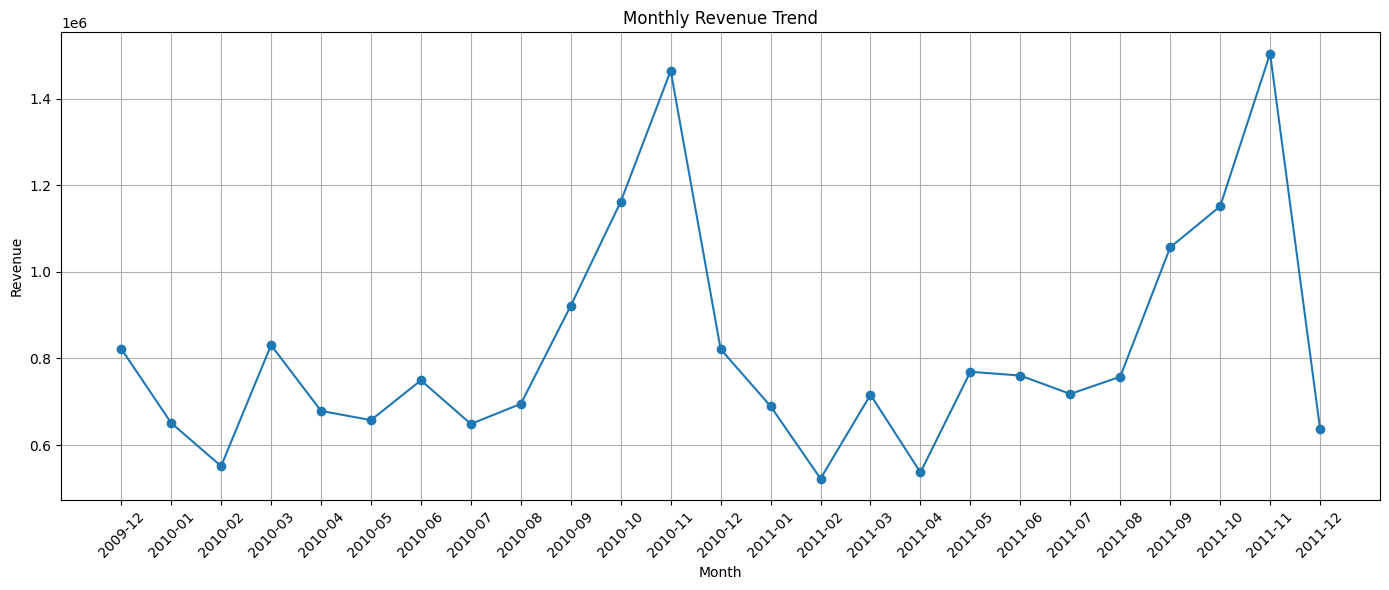

In [26]:
import matplotlib.pyplot as plt

monthly_revenue.index = monthly_revenue.index.astype(str)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# Extract day name
df_combined["DayOfWeek"] = (
    df_combined["InvoiceDate"].dt.day_name()
)

# Define weekday order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate revenue by weekday
weekday_revenue = (
    df_combined.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(day_order)
)

print("Revenue by Day of Week:")
print(weekday_revenue)

Revenue by Day of Week:
DayOfWeek
Monday       3581594.176
Tuesday      4078149.962
Wednesday    3488444.333
Thursday     4195212.762
Friday       3323908.883
Saturday        9803.050
Sunday       1799147.282
Name: Revenue, dtype: float64


In [28]:
# Extract transaction date
df_combined["Date"] = (
    df_combined["InvoiceDate"].dt.date
)

# Calculate daily revenue
daily_revenue = (
    df_combined.groupby(["Date", "DayOfWeek"])["Revenue"]
    .sum()
    .reset_index()
)

# Calculate average daily revenue and number of active dates
weekday_analysis = (
    daily_revenue.groupby("DayOfWeek")
    .agg(
        Average_Daily_Revenue=("Revenue", "mean"),
        Total_Active_Days=("Date", "nunique"),
        Total_Revenue=("Revenue", "sum")
    )
    .reindex(day_order)
)

print("Average Daily Revenue by Weekday:")
print(weekday_analysis.round(2))

Average Daily Revenue by Weekday:
           Average_Daily_Revenue  Total_Active_Days  Total_Revenue
DayOfWeek                                                         
Monday                  38102.07                 94     3581594.18
Tuesday                 39212.98                104     4078149.96
Wednesday               33542.73                104     3488444.33
Thursday                40730.22                103     4195212.76
Friday                  33574.84                 99     3323908.88
Saturday                 9803.05                  1        9803.05
Sunday                  18173.20                 99     1799147.28


In [29]:
# Extract transaction hour
df_combined["Hour"] = (
    df_combined["InvoiceDate"].dt.hour
)

# Calculate revenue by hour
hourly_revenue = (
    df_combined.groupby("Hour")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Hour:")
print(hourly_revenue)

Revenue by Hour:
Hour
12    2850377.671
10    2581131.333
13    2548467.544
11    2535325.463
15    2394943.792
14    2321684.731
9     1769631.031
16    1570143.801
17     861460.132
8      528185.570
18     273405.020
19     126830.350
7       75765.570
20      38904.190
6           4.250
21          0.000
Name: Revenue, dtype: float64


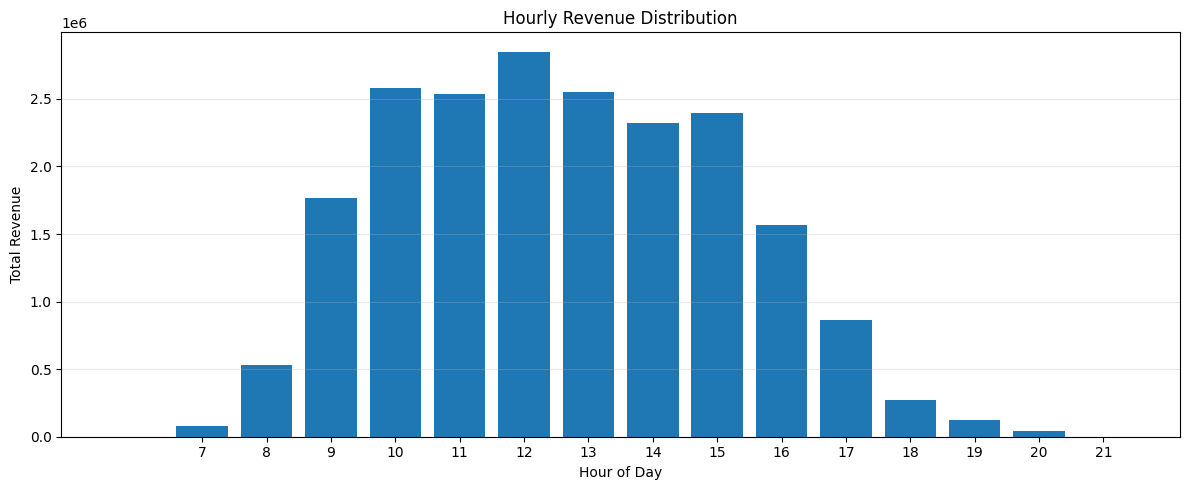

In [30]:
import matplotlib.pyplot as plt

hourly_revenue_sorted = hourly_revenue.sort_index()

plt.figure(figsize=(12, 5))

plt.bar(
    hourly_revenue_sorted.index,
    hourly_revenue_sorted.values
)

plt.title("Hourly Revenue Distribution")
plt.xlabel("Hour of Day")
plt.ylabel("Total Revenue")
plt.xticks(range(7, 22))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    # Cancellation analysis
    cancelled_records = df[df["IsCancelled"] == True]

    cancelled_invoices = (
        cancelled_records["InvoiceNo"].nunique()
    )

    # Return analysis
    return_records = df[df["IsReturn"] == True]

    return_invoices = (
        return_records["InvoiceNo"].nunique()
    )

    print("Total Records:", len(df))

    print("\nCancellation Analysis:")
    print("Cancelled Records:", len(cancelled_records))
    print("Cancelled Invoices:", cancelled_invoices)

    print("\nReturn Analysis:")
    print("Return Records:", len(return_records))
    print("Return Invoices:", return_invoices)

    # Check overlap
    overlap = df[
        (df["IsCancelled"] == True) &
        (df["IsReturn"] == True)
    ]

    print("\nRecords marked as both cancelled and returned:",
          len(overlap))


========== Year 2009-2010 ==========
Total Records: 518596

Cancellation Analysis:
Cancelled Records: 10182
Cancelled Invoices: 4592

Return Analysis:
Return Records: 12302
Return Invoices: 6712

Records marked as both cancelled and returned: 10181

========== Year 2010-2011 ==========
Total Records: 536642

Cancellation Analysis:
Cancelled Records: 9251
Cancelled Invoices: 3836

Return Analysis:
Return Records: 10587
Return Invoices: 5172

Records marked as both cancelled and returned: 9251

========== Combined Dataset ==========
Total Records: 1033036

Cancellation Analysis:
Cancelled Records: 19104
Cancelled Invoices: 8292

Return Analysis:
Return Records: 22496
Return Invoices: 11684

Records marked as both cancelled and returned: 19103


In [32]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    # Genuine return candidates excluding cancellations
    valid_returns = df[
        (df["IsReturn"] == True) &
        (df["IsCancelled"] == False)
    ]

    print("Non-Cancelled Return Records:",
          len(valid_returns))

    print("Non-Cancelled Return Invoices:",
          valid_returns["InvoiceNo"].nunique())

    print("Non-Cancelled Return Quantity:",
          valid_returns["Quantity"].sum())

    print("Non-Cancelled Return Revenue:",
          valid_returns["Revenue"].sum())



========== Year 2009-2010 ==========
Non-Cancelled Return Records: 2121
Non-Cancelled Return Invoices: 2121
Non-Cancelled Return Quantity: -366128
Non-Cancelled Return Revenue: 0.0

========== Year 2010-2011 ==========
Non-Cancelled Return Records: 1336
Non-Cancelled Return Invoices: 1336
Non-Cancelled Return Quantity: -206957
Non-Cancelled Return Revenue: 0.0

========== Combined Dataset ==========
Non-Cancelled Return Records: 3393
Non-Cancelled Return Invoices: 3393
Non-Cancelled Return Quantity: -569314
Non-Cancelled Return Revenue: 0.0


In [33]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    returns = df[
        (df["IsReturn"] == True) &
        (df["IsCancelled"] == False)
    ]

    print("Return Records:", len(returns))

    print("\nUnitPrice Analysis:")
    print("Positive UnitPrice:",
          (returns["UnitPrice"] > 0).sum())

    print("Zero UnitPrice:",
          (returns["UnitPrice"] == 0).sum())

    print("Negative UnitPrice:",
          (returns["UnitPrice"] < 0).sum())

    print("Missing UnitPrice:",
          returns["UnitPrice"].isna().sum())

    print("\nInvalid Price Records:",
          returns["IsInvalidPrice"].sum())

    print("Recorded Revenue:",
          returns["Revenue"].sum())

    print("Calculated Return Value:")
    print(
        (
            returns.loc[
                returns["UnitPrice"] > 0, "Quantity"
            ] *
            returns.loc[
                returns["UnitPrice"] > 0, "UnitPrice"
            ]
        ).sum()
    )


========== Year 2009-2010 ==========
Return Records: 2121

UnitPrice Analysis:
Positive UnitPrice: 0
Zero UnitPrice: 2121
Negative UnitPrice: 0
Missing UnitPrice: 0

Invalid Price Records: 2121
Recorded Revenue: 0.0
Calculated Return Value:
0.0

========== Year 2010-2011 ==========
Return Records: 1336

UnitPrice Analysis:
Positive UnitPrice: 0
Zero UnitPrice: 1336
Negative UnitPrice: 0
Missing UnitPrice: 0

Invalid Price Records: 1336
Recorded Revenue: 0.0
Calculated Return Value:
0.0

========== Combined Dataset ==========
Return Records: 3393

UnitPrice Analysis:
Positive UnitPrice: 0
Zero UnitPrice: 3393
Negative UnitPrice: 0
Missing UnitPrice: 0

Invalid Price Records: 3393
Recorded Revenue: 0.0
Calculated Return Value:
0.0


In [34]:
# Inspect return records in the combined dataset

return_records = df_combined[
    (df_combined["IsReturn"] == True) &
    (df_combined["IsCancelled"] == False)
]

print("Sample Return Records:")
print(
    return_records[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "IsCancelled",
            "IsReturn",
            "IsInvalidPrice",
            "Revenue"
        ]
    ].head(15).to_string(index=False)
)

print("\nTop 10 Return Descriptions:")
print(return_records["Description"].value_counts().head(10))

print("\nTop 10 Return StockCodes:")
print(return_records["StockCode"].value_counts().head(10))

Sample Return Records:
InvoiceNo StockCode     Description  Quantity  UnitPrice  IsCancelled  IsReturn  IsInvalidPrice  Revenue
   489464     21733    85123a mixed       -96        0.0        False      True            True      0.0
   489463     71477           short      -240        0.0        False      True            True      0.0
   489467    85123A     21733 mixed      -192        0.0        False      True            True      0.0
   489521     21646             NaN       -50        0.0        False      True            True      0.0
   489655     20683             NaN       -44        0.0        False      True            True      0.0
   489660     35956            lost     -1043        0.0        False      True            True      0.0
   489663    35605A         damages      -117        0.0        False      True            True      0.0
   489806     18010             NaN      -770        0.0        False      True            True      0.0
   489820     21133 invcd as 848

In [35]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    cancelled = df[df["IsCancelled"] == True]

    print("Cancelled Records:", len(cancelled))

    print("\nTop 10 Cancelled StockCodes:")
    print(cancelled["StockCode"].value_counts().head(10))

    print("\nTop 10 Cancelled Descriptions:")
    print(cancelled["Description"].value_counts().head(10))

    print("\nCancelled Quantity:")
    print(cancelled["Quantity"].sum())



========== Year 2009-2010 ==========
Cancelled Records: 10182

Top 10 Cancelled StockCodes:
StockCode
M         293
22138     184
22423     166
21232     128
79323W    125
21843     117
POST      103
21527      98
D          95
85123A     93
Name: count, dtype: int64

Top 10 Cancelled Descriptions:
Description
Manual                                293
BAKING SET 9 PIECE RETROSPOT          184
REGENCY CAKESTAND 3 TIER              166
STRAWBERRY CERAMIC TRINKET BOX        128
WHITE CHERRY LIGHTS                   125
POSTAGE                               103
Discount                               95
WHITE HANGING HEART T-LIGHT HOLDER     93
PINK CHERRY LIGHTS                     84
RED RETROSPOT CAKE STAND               69
Name: count, dtype: int64

Cancelled Quantity:
-213288

========== Year 2010-2011 ==========
Cancelled Records: 9251

Top 10 Cancelled StockCodes:
StockCode
M        244
22423    180
POST     126
22960     87
D         77
22720     73
S         60
21232     60
22699 

In [37]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    total_invoices = df["InvoiceNo"].nunique()

    cancelled_invoices = (
        df[df["IsCancelled"] == True]["InvoiceNo"]
        .nunique()
    )

    cancellation_rate = (
        cancelled_invoices / total_invoices
    ) * 100

    print("Total Unique Invoices:", total_invoices)
    print("Cancelled Invoices:", cancelled_invoices)
    print("Cancellation Rate:", round(cancellation_rate, 2), "%")


========== Year 2009-2010 ==========
Total Unique Invoices: 28816
Cancelled Invoices: 4592
Cancellation Rate: 15.94 %

========== Year 2010-2011 ==========
Total Unique Invoices: 25900
Cancelled Invoices: 3836
Cancellation Rate: 14.81 %

========== Combined Dataset ==========
Total Unique Invoices: 53628
Cancelled Invoices: 8292
Cancellation Rate: 15.46 %


In [38]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    cancelled = df[df["IsCancelled"] == True].copy()

    cancelled["CancelledValue"] = (
        cancelled["Quantity"].abs() *
        cancelled["UnitPrice"].abs()
    )

    total_cancelled_value = cancelled["CancelledValue"].sum()

    print(
        "Estimated Cancelled Transaction Value:",
        round(total_cancelled_value, 2)
    )

    print(
        "Cancelled Records with Positive UnitPrice:",
        len(cancelled[cancelled["UnitPrice"] > 0])
    )

    print(
        "Cancelled Records with Zero UnitPrice:",
        len(cancelled[cancelled["UnitPrice"] == 0])
    )

    print(
        "Cancelled Records with Negative UnitPrice:",
        len(cancelled[cancelled["UnitPrice"] < 0])
    )


========== Year 2009-2010 ==========
Estimated Cancelled Transaction Value: 630182.22
Cancelled Records with Positive UnitPrice: 10182
Cancelled Records with Zero UnitPrice: 0
Cancelled Records with Negative UnitPrice: 0

========== Year 2010-2011 ==========
Estimated Cancelled Transaction Value: 893979.73
Cancelled Records with Positive UnitPrice: 9251
Cancelled Records with Zero UnitPrice: 0
Cancelled Records with Negative UnitPrice: 0

========== Combined Dataset ==========
Estimated Cancelled Transaction Value: 1462797.75
Cancelled Records with Positive UnitPrice: 19104
Cancelled Records with Zero UnitPrice: 0
Cancelled Records with Negative UnitPrice: 0


In [39]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    print("Total Records:", len(df))

    print("Duplicate Records:", df.duplicated().sum())

    print("Missing CustomerID:", df["CustomerID"].isna().sum())

    print("Missing Description:", df["Description"].isna().sum())

    print("Zero UnitPrice:", (df["UnitPrice"] == 0).sum())

    print("Negative UnitPrice:", (df["UnitPrice"] < 0).sum())

    print("Zero Quantity:", (df["Quantity"] == 0).sum())

    print("Negative Quantity:", (df["Quantity"] < 0).sum())

    print("Missing InvoiceDate:", df["InvoiceDate"].isna().sum())


========== Year 2009-2010 ==========
Total Records: 518596
Duplicate Records: 0
Missing CustomerID: 107833
Missing Description: 2928
Zero UnitPrice: 3681
Negative UnitPrice: 3
Zero Quantity: 0
Negative Quantity: 12302
Missing InvoiceDate: 0

========== Year 2010-2011 ==========
Total Records: 536642
Duplicate Records: 0
Missing CustomerID: 135037
Missing Description: 1454
Zero UnitPrice: 2510
Negative UnitPrice: 2
Zero Quantity: 0
Negative Quantity: 10587
Missing InvoiceDate: 0

========== Combined Dataset ==========
Total Records: 1033036
Duplicate Records: 0
Missing CustomerID: 235151
Missing Description: 4275
Zero UnitPrice: 6014
Negative UnitPrice: 5
Zero Quantity: 0
Negative Quantity: 22496
Missing InvoiceDate: 0


In [40]:
df = df_combined

print("Total Records:", len(df))
print("Duplicate Records:", df.duplicated().sum())
print("Missing CustomerID:", df["CustomerID"].isna().sum())
print("Missing Description:", df["Description"].isna().sum())
print("Zero UnitPrice:", (df["UnitPrice"] == 0).sum())
print("Negative UnitPrice:", (df["UnitPrice"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Missing InvoiceDate:", df["InvoiceDate"].isna().sum())

Total Records: 1033036
Duplicate Records: 0
Missing CustomerID: 235151
Missing Description: 4275
Zero UnitPrice: 6014
Negative UnitPrice: 5
Zero Quantity: 0
Negative Quantity: 22496
Missing InvoiceDate: 0


In [41]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    print("Cancelled Flag:", df["IsCancelled"].sum())

    print("Return Flag:", df["IsReturn"].sum())

    print("Invalid Price Flag:", df["IsInvalidPrice"].sum())

    print("Cancelled but not flagged as Return:",
          ((df["IsCancelled"]) & (~df["IsReturn"])).sum())

    print("Invalid Price but positive UnitPrice:",
          ((df["IsInvalidPrice"]) & (df["UnitPrice"] > 0)).sum())

    print("Valid Price but flagged Invalid:",
          ((~df["IsInvalidPrice"]) & (df["UnitPrice"] <= 0)).sum())


========== Year 2009-2010 ==========
Cancelled Flag: 10182
Return Flag: 12302
Invalid Price Flag: 3684
Cancelled but not flagged as Return: 1
Invalid Price but positive UnitPrice: 0
Valid Price but flagged Invalid: 0

========== Year 2010-2011 ==========
Cancelled Flag: 9251
Return Flag: 10587
Invalid Price Flag: 2512
Cancelled but not flagged as Return: 0
Invalid Price but positive UnitPrice: 0
Valid Price but flagged Invalid: 0

========== Combined Dataset ==========
Cancelled Flag: 19104
Return Flag: 22496
Invalid Price Flag: 6019
Cancelled but not flagged as Return: 1
Invalid Price but positive UnitPrice: 0
Valid Price but flagged Invalid: 0


In [42]:
exception = df1[
    (df1["IsCancelled"] == True) &
    (df1["IsReturn"] == False)
]

exception

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsReturn,IsInvalidPrice,Revenue,Year,Month
75972,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom,True,False,False,0.0,2010,2


In [43]:
expected_revenue = np.where(
    (~df_combined["IsCancelled"]) &
    (df_combined["UnitPrice"] > 0),
    df_combined["Quantity"] * df_combined["UnitPrice"],
    0
)

mismatch = (
    df_combined["Revenue"] != expected_revenue
).sum()

print("Revenue Mismatches:", mismatch)
print("Actual Total Revenue:", df_combined["Revenue"].sum())
print("Expected Total Revenue:", expected_revenue.sum())

Revenue Mismatches: 132252
Actual Total Revenue: 20476260.448000003
Expected Total Revenue: 20476260.448000003


In [44]:
expected_revenue = np.where(
    (~df_combined["IsCancelled"]) &
    (df_combined["UnitPrice"] > 0),
    df_combined["Quantity"] * df_combined["UnitPrice"],
    0
)

mismatch = ~np.isclose(
    df_combined["Revenue"],
    expected_revenue,
    rtol=1e-09,
    atol=1e-09
)

print("Revenue Mismatches:", mismatch.sum())
print(
    "Maximum Absolute Difference:",
    np.abs(
        df_combined["Revenue"] - expected_revenue
    ).max()
)

Revenue Mismatches: 0
Maximum Absolute Difference: 4.547473508864641e-13


In [45]:
print("========== Numerical Column Summary ==========")

print(df_combined[
    ["Quantity", "UnitPrice", "Revenue"]
].describe())

print("\n========== Unique Values ==========")

for col in ["IsCancelled", "IsReturn", "IsInvalidPrice", "Year", "Month"]:
    print(f"\n{col}:")
    print(df_combined[col].value_counts(dropna=False).sort_index())


========== Numerical Column Summary ==========
           Quantity     UnitPrice       Revenue
count  1.033036e+06  1.033036e+06  1.033036e+06
mean   1.007688e+01  4.613980e+00  1.982144e+01
std    1.751976e+02  1.223975e+02  2.032231e+02
min   -8.099500e+04 -5.359436e+04  0.000000e+00
25%    1.000000e+00  1.250000e+00  3.750000e+00
50%    3.000000e+00  2.100000e+00  9.920000e+00
75%    1.000000e+01  4.150000e+00  1.770000e+01
max    8.099500e+04  3.897000e+04  1.684696e+05

========== Unique Values ==========

IsCancelled:
IsCancelled
False    1013932
True       19104
Name: count, dtype: int64

IsReturn:
IsReturn
False    1010540
True       22496
Name: count, dtype: int64

IsInvalidPrice:
IsInvalidPrice
False    1027017
True        6019
Name: count, dtype: int64

Year:
Year
2009     44722
2010    493653
2011    494661
Name: count, dtype: int64

Month:
Month
1      66134
2      56537
3      77424
4      63348
5      71690
6      76078
7      72259
8      68003
9      91468
10    118218

In [46]:
print("========== Extreme Quantity Records ==========")

print(
    df_combined.loc[
        df_combined["Quantity"].abs().nlargest(5).index,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "IsCancelled"]
    ]
)

print("\n========== Extreme UnitPrice Records ==========")

print(
    df_combined.loc[
        df_combined["UnitPrice"].abs().nlargest(5).index,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "IsCancelled"]
    ]
)

print("\n========== Extreme Revenue Records ==========")

print(
    df_combined.nlargest(
        5, "Revenue"
    )[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue"]
    ]
)

========== Extreme Quantity Records ==========
        InvoiceNo StockCode                         Description  Quantity  \
1031554    581483     23843         PAPER CRAFT , LITTLE BIRDIE     80995   
1031555   C581484     23843         PAPER CRAFT , LITTLE BIRDIE    -80995   
557400     541431     23166      MEDIUM CERAMIC TOP STORAGE JAR     74215   
557405    C541433     23166      MEDIUM CERAMIC TOP STORAGE JAR    -74215   
89849      497946     37410  BLACK AND WHITE PAISLEY FLOWER MUG     19152   

         UnitPrice   Revenue  IsCancelled  
1031554       2.08  168469.6        False  
1031555       2.08       0.0         True  
557400        1.04   77183.6        False  
557405        1.04       0.0         True  
89849         0.10    1915.2        False  

========== Extreme UnitPrice Records ==========
       InvoiceNo StockCode      Description  Quantity  UnitPrice  Revenue  \
177338   A506401         B  Adjust bad debt         1  -53594.36      0.0   
273025   A516228       

In [47]:
invoice_revenue = (
    df_combined[
        df_combined["IsCancelled"] == False
    ]
    .groupby("InvoiceNo")
    .agg(
        InvoiceRevenue=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        CustomerID=("CustomerID", "first"),
        Country=("Country", "first")
    )
    .sort_values("InvoiceRevenue", ascending=False)
)

print(invoice_revenue.head(10))

           InvoiceRevenue  TotalQuantity  UniqueProducts  CustomerID  \
InvoiceNo                                                              
581483          168469.60          80995               1     16446.0   
541431           77183.60          74215               1     12346.0   
574941           52940.94          14149             101         NaN   
576365           50653.91          13956              99         NaN   
533027           49844.99          13387             111         NaN   
531516           45332.97          12410             115         NaN   
493819           44051.60          25018              94     14156.0   
556444           38970.00             60               1     15098.0   
524181           33167.80           8820              14     17450.0   
567423           31698.16          12572              12     17450.0   

                  Country  
InvoiceNo                  
581483     United Kingdom  
541431     United Kingdom  
574941     United Kingd

In [48]:
total = len(df_combined)

quality_metrics = {
    "Missing CustomerID": df_combined["CustomerID"].isna().sum(),
    "Missing Description": df_combined["Description"].isna().sum(),
    "Zero UnitPrice": (df_combined["UnitPrice"] == 0).sum(),
    "Negative UnitPrice": (df_combined["UnitPrice"] < 0).sum(),
    "Negative Quantity": (df_combined["Quantity"] < 0).sum()
}

for metric, count in quality_metrics.items():

    percentage = (count / total) * 100

    print(
        f"{metric}: {count:,} "
        f"({percentage:.2f}%)"
    )

Missing CustomerID: 235,151 (22.76%)
Missing Description: 4,275 (0.41%)
Zero UnitPrice: 6,014 (0.58%)
Negative UnitPrice: 5 (0.00%)
Negative Quantity: 22,496 (2.18%)
